<a href="https://colab.research.google.com/github/Lyra0710/Blog-and-News-Website/blob/main/hw4.5/HW4_5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# HW4.5 — GPU Assignment II: Training Throughput and Memory Engineering

In [10]:
%pip install --no-deps --force-reinstall "datasets==3.6.0"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 491.5/491.5 kB 6.7 MB/s eta 0:00:00
  Attempting uninstall: datasets
    Found existing installation: datasets 5.1.0
    Uninstalling datasets-5.1.0:
      Successfully uninstalled datasets-5.1.0
Note: you may need to restart the kernel to use updated packages.


In [1]:
import sys
import torch

print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "GPU memory:",
        round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2),
        "GiB"
    )

Python: 3.10.13
PyTorch: 2.5.1+cu124
CUDA available: True
GPU: NVIDIA GeForce RTX 4090
GPU memory: 23.99 GiB


## Part A — Batch scaling to the memory wall

Getting configs from BERT baseline implementation

In [3]:
import json

notebook_path = PROJECT_DIR / "BERT_Baseline.ipynb"

with notebook_path.open(encoding="utf-8") as file:
    notebook = json.load(file)

# Display the original notebook's code cells with their indices.
for index, cell in enumerate(notebook["cells"]):
    if cell["cell_type"] == "code":
        source = "".join(cell["source"])
        print(f"\n{'=' * 20} CELL {index} {'=' * 20}")
        print(source[:3000])


==================== CELL 3 ====================
import torch
import platform

print("Operating system:", platform.system())
print("PyTorch version:", torch.__version__)
print("CUDA version:", torch.version.cuda)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU count:", torch.cuda.device_count())

    for i in range(torch.cuda.device_count()):
        gpu = torch.cuda.get_device_properties(i)
        print(f"GPU {i}: {gpu.name}")
        print(f"VRAM: {gpu.total_memory / 1024**3:.2f} GiB")

==================== CELL 6 ====================
import importlib.util
import subprocess
import sys

# Install Hugging Face Datasets if necessary.
if importlib.util.find_spec("datasets") is None:
    subprocess.run(
        [sys.executable, "-m", "pip", "install", "datasets"],
        check=True
    )

from datasets import load_dataset

# Load the Twitter sentiment dataset.
dataset = load_dataset(
    "cardiffnlp/tweet_eval",
    "sentiment",
    spl

In [4]:
# Find the original learning rate, epoch count, and optimizer setup.
for index, cell in enumerate(notebook["cells"]):
    source = "".join(cell.get("source", []))

    if any(name in source for name in ["LEARNING_RATE =", "EPOCHS =", "AdamW("]):
        print(f"\n--- Original cell {index} ---")
        print(source[:2000])


--- Original cell 16 ---
# Reset the model and optimizer for a fresh baseline run.
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

model = BertForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=NUM_LABELS
).to(device)

optimizer = AdamW(model.parameters(), lr=LEARNING_RATE)

# Output paths.
OUTPUT_DIR = Path("/app/data266-2383/hw4.5/outputs")
MODEL_DIR = OUTPUT_DIR / "models" / "bert_baseline"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

history = []
best_val_loss = float("inf")
best_epoch = 0

torch.cuda.reset_peak_memory_stats(device)
torch.cuda.synchronize(device)
start_time = time.perf_counter()

for epoch in range(EPOCHS):
    epoch_start = time.perf_counter()

    # Training
    model.train()
    total_train_loss = 0

    for input_ids, attention_mask, labels in train_loader:
        input_ids = input_ids.to(device)
        attention_mask = attention_mask.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outpu

In [5]:
# Inspect the setup cells immediately before training.
for index in [12, 15]:
    cell = notebook["cells"][index]
    print(f"\n--- Original cell {index} ---")
    print("".join(cell.get("source", [])))


--- Original cell 12 ---
Initialize BERT and create DataLoaders

--- Original cell 15 ---
Train and validate


In [6]:
metrics_path = PROJECT_DIR / "METRICS.md"

for line in metrics_path.read_text(encoding="utf-8").splitlines():
    if "Learning rate:" in line or "Epochs:" in line:
        print(line)

- Epochs: 4
- Learning rate: 2e-05


### 1. Preparing the original BERT dataset

In [11]:
# Part A: Verify the training environment before running experiments.
import torch
import datasets
import transformers

from datasets import load_dataset
from sklearn.model_selection import train_test_split
from torch.utils.data import TensorDataset, DataLoader
from transformers import BertTokenizer, BertForSequenceClassification
from torch.optim import AdamW

print("PyTorch:", torch.__version__)
print("Datasets:", datasets.__version__)
print("Transformers:", transformers.__version__)
print("CUDA available:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0))
print("All required imports successful.")

PyTorch: 2.5.1+cu124
Datasets: 3.6.0
Transformers: 4.57.6
CUDA available: True
GPU: NVIDIA GeForce RTX 4090
All required imports successful.


Getting data

In [12]:
import random
import numpy as np

# Use the exact configuration from HW4.a.
SEED = 42
SLICE = 0
SUBSET_SIZE = 5000
MODEL_NAME = "bert-base-uncased"
MAX_LENGTH = 128
NUM_LABELS = 3
EPOCHS = 4
LEARNING_RATE = 2e-5
BASELINE_BATCH_SIZE = 16

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# Load the same Twitter sentiment dataset.
dataset = load_dataset(
    "cardiffnlp/tweet_eval",
    "sentiment",
    split="train"
)

# Select the same 5,000 consecutive rows.
end_row = min(SLICE + SUBSET_SIZE, len(dataset))
subset = dataset.select(range(SLICE, end_row))

# Recreate the original stratified 70/15/15 split.
train_data, remaining_data = train_test_split(
    list(subset),
    test_size=0.30,
    random_state=SEED,
    stratify=subset["label"]
)

val_data, test_data = train_test_split(
    remaining_data,
    test_size=0.50,
    random_state=SEED,
    stratify=[row["label"] for row in remaining_data]
)

print(f"Original row range: {SLICE} to {end_row - 1}")
print(f"Training samples: {len(train_data)}")
print(f"Validation samples: {len(val_data)}")
print(f"Test samples: {len(test_data)}")

Original row range: 0 to 4999
Training samples: 3500
Validation samples: 750
Test samples: 750


### 2. Tokenizing the dataset

In [13]:
# Tokenize the tweets using the original HW4.a settings.
tokenizer = BertTokenizer.from_pretrained(MODEL_NAME)

def prepare_dataset(data):
    texts = [row["text"] for row in data]
    labels = torch.tensor(
        [row["label"] for row in data],
        dtype=torch.long
    )

    encoded = tokenizer(
        texts,
        padding="max_length",
        truncation=True,
        max_length=MAX_LENGTH,
        return_tensors="pt"
    )

    return TensorDataset(
        encoded["input_ids"],
        encoded["attention_mask"],
        labels
    )

train_dataset = prepare_dataset(train_data)
val_dataset = prepare_dataset(val_data)
test_dataset = prepare_dataset(test_data)

print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Test samples:", len(test_dataset))
print("Input tensor shape:", train_dataset.tensors[0].shape)

Training samples: 3500
Validation samples: 750
Test samples: 750
Input tensor shape: torch.Size([3500, 128])


Train at batch size 16

In [14]:
import time
from torch.utils.data import DataLoader
from transformers import BertForSequenceClassification
from torch.optim import AdamW

# Original HW4.a batch size and training settings.
batch_size = 16
device = torch.device("cuda")

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False
)

# Reset the seed and initialize a fresh BERT model.
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

model = BertForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=NUM_LABELS
).to(device)

optimizer = AdamW(model.parameters(), lr=LEARNING_RATE)

torch.cuda.reset_peak_memory_stats(device)
results = []

for epoch in range(EPOCHS):
    model.train()
    total_loss = 0.0

    torch.cuda.synchronize()
    start_time = time.perf_counter()

    # Training loop from HW4.a.
    for input_ids, attention_mask, labels in train_loader:
        input_ids = input_ids.to(device)
        attention_mask = attention_mask.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            labels=labels
        )

        loss = outputs.loss
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * labels.size(0)

    # Validation loop from HW4.a.
    model.eval()
    correct = 0

    with torch.no_grad():
        for input_ids, attention_mask, labels in val_loader:
            input_ids = input_ids.to(device)
            attention_mask = attention_mask.to(device)
            labels = labels.to(device)

            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask,
                labels=labels
            )

            predictions = outputs.logits.argmax(dim=1)
            correct += (predictions == labels).sum().item()

    torch.cuda.synchronize()
    epoch_time = time.perf_counter() - start_time

    # Throughput uses training samples only and training + validation epoch time.
    throughput = len(train_dataset) / epoch_time
    peak_memory = torch.cuda.max_memory_allocated(device) / 1024**3

    result = {
        "batch_size": batch_size,
        "epoch": epoch + 1,
        "epoch_time_s": round(epoch_time, 2),
        "throughput_samples_s": round(throughput, 2),
        "peak_memory_gib": round(peak_memory, 2),
        "val_accuracy": round(correct / len(val_dataset), 4)
    }
    results.append(result)

    print(result, flush=True)

print("\nBatch size 16 complete.")

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at bert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


{'batch_size': 16, 'epoch': 1, 'epoch_time_s': 11.12, 'throughput_samples_s': 314.88, 'peak_memory_gib': 2.47, 'val_accuracy': 0.676}
{'batch_size': 16, 'epoch': 2, 'epoch_time_s': 10.77, 'throughput_samples_s': 324.89, 'peak_memory_gib': 2.47, 'val_accuracy': 0.692}
{'batch_size': 16, 'epoch': 3, 'epoch_time_s': 10.61, 'throughput_samples_s': 329.83, 'peak_memory_gib': 2.47, 'val_accuracy': 0.684}
{'batch_size': 16, 'epoch': 4, 'epoch_time_s': 10.61, 'throughput_samples_s': 329.91, 'peak_memory_gib': 2.47, 'val_accuracy': 0.6853}

Batch size 16 complete.


### 3. Batch-size scaling sweep

In [16]:
import gc
import time
import pandas as pd
from pathlib import Path
from tqdm.auto import tqdm

# Batch sizes increase by powers of two.
BATCH_SIZES = [16, 32, 64, 128, 256, 512, 1024, 2048, 4096]
MAX_EPOCH_SECONDS = 60

OUTPUT_FILE = Path(
    "/app/data266-2383/hw4.5/outputs/part_a_batch_scaling.csv"
)
OUTPUT_FILE.parent.mkdir(parents=True, exist_ok=True)

part_a_results = []
batch_status = []

# Release the model from the earlier experiment.
for name in ["model", "optimizer", "train_loader", "val_loader"]:
    if name in globals():
        del globals()[name]

gc.collect()
torch.cuda.empty_cache()

for batch_size in BATCH_SIZES:
    print(f"\n{'=' * 50}")
    print(f"Testing batch size: {batch_size}", flush=True)

    status = "completed"

    try:
        # Keep the original HW4.a dataset and training settings.
        train_loader = DataLoader(
            train_dataset,
            batch_size=batch_size,
            shuffle=True
        )

        val_loader = DataLoader(
            val_dataset,
            batch_size=batch_size,
            shuffle=False
        )

        # Initialize fresh BERT weights for every batch size.
        torch.manual_seed(SEED)
        torch.cuda.manual_seed_all(SEED)

        model = BertForSequenceClassification.from_pretrained(
            MODEL_NAME,
            num_labels=NUM_LABELS
        ).to(device)

        optimizer = AdamW(model.parameters(), lr=LEARNING_RATE)

        torch.cuda.reset_peak_memory_stats(device)

        for epoch in range(EPOCHS):
            model.train()

            torch.cuda.synchronize(device)
            epoch_start = time.perf_counter()

            # Training progress bar.
            progress = tqdm(
                train_loader,
                desc=f"Batch {batch_size} | Epoch {epoch + 1}/{EPOCHS}",
                leave=False
            )

            for input_ids, attention_mask, labels in progress:
                input_ids = input_ids.to(device)
                attention_mask = attention_mask.to(device)
                labels = labels.to(device)

                optimizer.zero_grad()

                outputs = model(
                    input_ids=input_ids,
                    attention_mask=attention_mask,
                    labels=labels
                )

                loss = outputs.loss
                loss.backward()
                optimizer.step()

                # Synchronize before checking elapsed GPU time.
                torch.cuda.synchronize(device)
                elapsed = time.perf_counter() - epoch_start

                progress.set_postfix(
                    time=f"{elapsed:.1f}s",
                    peak_gib=f"{torch.cuda.max_memory_allocated(device) / 1024**3:.2f}"
                )

                # This is a soft timeout, checked after each batch.
                if elapsed > MAX_EPOCH_SECONDS:
                    status = "too_slow"
                    break

            progress.close()

            if status == "too_slow":
                print(
                    f"Batch {batch_size}: epoch exceeded "
                    f"{MAX_EPOCH_SECONDS} seconds. "
                    "Stopping this batch size.",
                    flush=True
                )
                break

            # Validation using the original HW4.a approach.
            model.eval()
            correct = 0

            with torch.no_grad():
                for input_ids, attention_mask, labels in val_loader:
                    input_ids = input_ids.to(device)
                    attention_mask = attention_mask.to(device)
                    labels = labels.to(device)

                    outputs = model(
                        input_ids=input_ids,
                        attention_mask=attention_mask,
                        labels=labels
                    )

                    predictions = outputs.logits.argmax(dim=1)
                    correct += (predictions == labels).sum().item()

            torch.cuda.synchronize(device)
            epoch_time = time.perf_counter() - epoch_start

            result = {
                "batch_size": batch_size,
                "epoch": epoch + 1,
                "epoch_time_s": round(epoch_time, 2),
                "throughput_samples_s": round(
                    len(train_dataset) / epoch_time, 2
                ),
                "peak_memory_gib": round(
                    torch.cuda.max_memory_allocated(device) / 1024**3, 2
                ),
                "val_accuracy": round(
                    correct / len(val_dataset), 4
                )
            }

            part_a_results.append(result)

            # Save every completed epoch immediately.
            pd.DataFrame(part_a_results).to_csv(
                OUTPUT_FILE,
                index=False
            )

            print(result, flush=True)

    except torch.cuda.OutOfMemoryError:
        status = "oom"
        print(
            f"\nConfirmed CUDA out-of-memory at batch size {batch_size}.",
            flush=True
        )

    finally:
        batch_status.append({
            "batch_size": batch_size,
            "status": status
        })

        # Release all tensors and model memory before the next test.
        for name in [
            "outputs", "loss", "input_ids", "attention_mask",
            "labels", "predictions", "model", "optimizer",
            "train_loader", "val_loader"
        ]:
            if name in globals():
                del globals()[name]

        gc.collect()
        torch.cuda.empty_cache()

        pd.DataFrame(batch_status).to_csv(
            OUTPUT_FILE.parent / "part_a_batch_status.csv",
            index=False
        )

    if status in ["oom", "too_slow"]:
        print(f"\nStopping scaling sweep: {status.upper()}")
        break

print("\nPart A batch-scaling sweep finished.")

print("\nBatch status:")
print(pd.DataFrame(batch_status).to_string(index=False))

if part_a_results:
    print("\nCompleted epoch measurements:")
    print(pd.DataFrame(part_a_results).to_string(index=False))

print("\nResults saved to:", OUTPUT_FILE)


Testing batch size: 16


Some weights of BertForSequenceClassification were not initialized from the model checkpoint at bert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


{'batch_size': 16, 'epoch': 1, 'epoch_time_s': 16.27, 'throughput_samples_s': 215.06, 'peak_memory_gib': 2.47, 'val_accuracy': 0.6813}


{'batch_size': 16, 'epoch': 2, 'epoch_time_s': 11.33, 'throughput_samples_s': 308.92, 'peak_memory_gib': 2.47, 'val_accuracy': 0.684}


{'batch_size': 16, 'epoch': 3, 'epoch_time_s': 11.25, 'throughput_samples_s': 311.13, 'peak_memory_gib': 2.47, 'val_accuracy': 0.684}


...

{'batch_size': 256, 'epoch': 3, 'epoch_time_s': 7.02, 'throughput_samples_s': 498.73, 'peak_memory_gib': 20.51, 'val_accuracy': 0.612}


{'batch_size': 256, 'epoch': 4, 'epoch_time_s': 7.02, 'throughput_samples_s': 498.76, 'peak_memory_gib': 20.51, 'val_accuracy': 0.6587}

Testing batch size: 512


Some weights of BertForSequenceClassification were not initialized from the model checkpoint at bert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
                                                                                        

Batch 512: epoch exceeded 60 seconds. Stopping this batch size.



Stopping scaling sweep: TOO_SLOW

Part A batch-scaling sweep finished.

Batch status:
 batch_size    status
         16 completed
         32 completed
         64 completed
        128 completed
        256 completed
        512  too_slow

Completed epoch measurements:
 batch_size  epoch  epoch_time_s  throughput_samples_s  peak_memory_gib  val_accuracy
         16      1         16.27                215.06             2.47        0.6813
         16      2         11.33                308.92             2.47        0.6840
         16      3         11.25                311.13             2.47        0.6840
         16      4         11.21                312.27             2.47        0.6920
         32      1          8.77                399.15             3.72        0.6693
         32      2          8.62                405.94             3.72        0.6773
         32      3          8.65                404.81             3.72        0.6840
         32      4          8.65        

Isolated memory-wall test

In [17]:
import subprocess
from pathlib import Path

# Save one batch of the already-prepared training data.
TEST_DIR = Path("/tmp/bert_memory_test")
TEST_DIR.mkdir(exist_ok=True)

torch.save(
    {
        "input_ids": train_dataset.tensors[0][:512],
        "attention_mask": train_dataset.tensors[1][:512],
        "labels": train_dataset.tensors[2][:512]
    },
    TEST_DIR / "batch.pt"
)

# Run the memory test in a separate Python process.
test_script = TEST_DIR / "test_batch.py"

test_script.write_text("""
import torch
from transformers import BertForSequenceClassification
from torch.optim import AdamW

BATCH_SIZE = 512
device = torch.device("cuda")

try:
    data = torch.load(
        "/tmp/bert_memory_test/batch.pt",
        weights_only=True
    )

    torch.manual_seed(42)
    torch.cuda.manual_seed_all(42)

    model = BertForSequenceClassification.from_pretrained(
        "bert-base-uncased",
        num_labels=3
    ).to(device)

    optimizer = AdamW(model.parameters(), lr=2e-5)

    model.train()
    torch.cuda.reset_peak_memory_stats(device)

    print("Starting batch size 512 training step...", flush=True)

    optimizer.zero_grad()

    outputs = model(
        input_ids=data["input_ids"].to(device),
        attention_mask=data["attention_mask"].to(device),
        labels=data["labels"].to(device)
    )

    outputs.loss.backward()
    optimizer.step()

    torch.cuda.synchronize()

    print("RESULT: SUCCESS", flush=True)
    print(
        "Peak allocated GPU memory:",
        round(torch.cuda.max_memory_allocated() / 1024**3, 2),
        "GiB",
        flush=True
    )

except torch.cuda.OutOfMemoryError:
    print("RESULT: CUDA OUT OF MEMORY", flush=True)

""", encoding="utf-8")

print("Running isolated batch-512 test...", flush=True)

try:
    subprocess.run(
        ["python", "-u", str(test_script)],
        timeout=90,
        check=True
    )

except subprocess.TimeoutExpired:
    print("\nRESULT: TIMEOUT")
    print("Batch 512 did not finish within 90 seconds.")
    print("This is NOT confirmation of CUDA OOM.")

except subprocess.CalledProcessError as error:
    print("\nRESULT: PROCESS FAILED")
    print("Exit code:", error.returncode)
    print("Inspect the error above before interpreting the result.")

Running isolated batch-512 test...


Some weights of BertForSequenceClassification were not initialized from the model checkpoint at bert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Starting batch size 512 training step...

RESULT: TIMEOUT
Batch 512 did not finish within 90 seconds.
This is NOT confirmation of CUDA OOM.


### 4. throughput plot

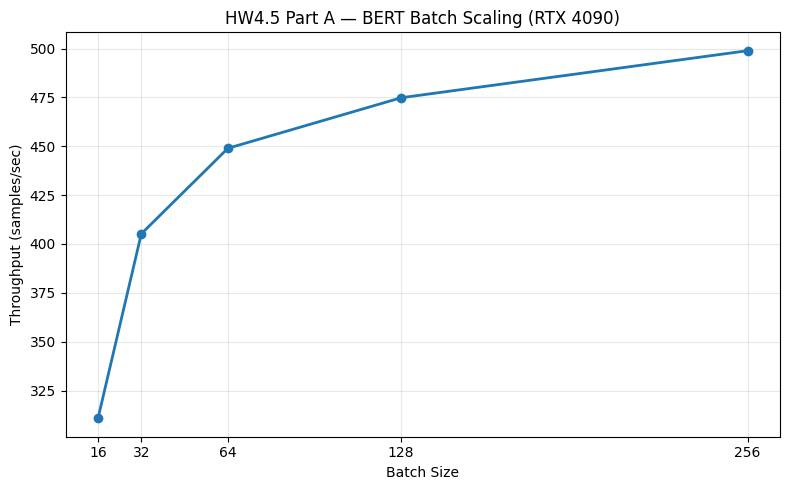


Batch-scaling summary:
 batch_size  throughput  epoch_time  peak_memory
         16      310.77       11.26         2.47
         32      405.20        8.64         3.72
         64      448.95        7.80         6.09
        128      474.80        7.37        10.94
        256      498.88        7.02        20.51

Figure saved to: /app/data266-2383/hw4.5/outputs/part_a_throughput.png


In [18]:
import matplotlib.pyplot as plt

# Load the completed batch-scaling measurements.
results_df = pd.read_csv(
    "/app/data266-2383/hw4.5/outputs/part_a_batch_scaling.csv"
)

# Use epochs 2–4 to reduce first-epoch warm-up effects.
summary = (
    results_df[results_df["epoch"] >= 2]
    .groupby("batch_size", as_index=False)
    .agg(
        throughput=("throughput_samples_s", "mean"),
        epoch_time=("epoch_time_s", "mean"),
        peak_memory=("peak_memory_gib", "max")
    )
)

# Plot throughput against batch size.
plt.figure(figsize=(8, 5))
plt.plot(
    summary["batch_size"],
    summary["throughput"],
    marker="o",
    linewidth=2
)

plt.xlabel("Batch Size")
plt.ylabel("Throughput (samples/sec)")
plt.title("HW4.5 Part A — BERT Batch Scaling (RTX 4090)")
plt.xticks(summary["batch_size"])
plt.grid(alpha=0.3)
plt.tight_layout()

figure_path = (
    "/app/data266-2383/hw4.5/outputs/part_a_throughput.png"
)

plt.savefig(figure_path, dpi=150)
plt.show()

print("\nBatch-scaling summary:")
print(summary.round(2).to_string(index=False))
print("\nFigure saved to:", figure_path)

Adding to METRICS.md

In [19]:
from pathlib import Path
import pandas as pd

OUTPUT_DIR = Path("/app/data266-2383/hw4.5/outputs")
METRICS_PATH = OUTPUT_DIR.parent / "METRICS.md"

# Load actual Part A experiment results.
df = pd.read_csv(OUTPUT_DIR / "part_a_batch_scaling.csv")
status_df = pd.read_csv(OUTPUT_DIR / "part_a_batch_status.csv")

# Use epochs 2–4 to exclude first-epoch warm-up effects.
summary = (
    df[df["epoch"] >= 2]
    .groupby("batch_size", as_index=False)
    .agg(
        throughput=("throughput_samples_s", "mean"),
        epoch_time=("epoch_time_s", "mean"),
        peak_memory=("peak_memory_gib", "max")
    )
)

# Identify the largest completed batch and fastest configuration.
completed = status_df.loc[
    status_df["status"] == "completed", "batch_size"
]

largest_batch = int(completed.max())
best = summary.loc[summary["throughput"].idxmax()]

# Generate the Markdown table from measured values.
table_rows = [
    "| Batch size | Throughput (samples/s) | Time/epoch (s) | Peak memory (GiB) |",
    "|---|---:|---:|---:|"
]

for _, row in summary.iterrows():
    table_rows.append(
        f"| {int(row['batch_size'])} | "
        f"{row['throughput']:.2f} | "
        f"{row['epoch_time']:.2f} | "
        f"{row['peak_memory']:.2f} |"
    )

status_lines = [
    f"- Batch size {int(row['batch_size'])}: {row['status']}"
    for _, row in status_df.iterrows()
]

part_a_text = "\n".join([
    "## HW4.5 Part A — Batch Scaling (RTX 4090)",
    "",
    "Throughput and time per epoch are averaged over epochs 2–4.",
    "Epoch duration includes training and validation.",
    "",
    *table_rows,
    "",
    f"- Largest batch completing all epochs: **{largest_batch}**",
    f"- Highest measured throughput: **{best['throughput']:.2f} samples/s** "
    f"at batch size **{int(best['batch_size'])}**",
    "",
    "### Batch Test Status",
    *status_lines,
    "",
    "A timeout is not evidence of CUDA out-of-memory.",
])

# Preserve other sections and replace Part A if it already exists.
start_marker = "<!-- PART_A_START -->"
end_marker = "<!-- PART_A_END -->"

existing = METRICS_PATH.read_text(encoding="utf-8") if METRICS_PATH.exists() else ""

section = f"{start_marker}\n{part_a_text}\n{end_marker}"

if start_marker in existing and end_marker in existing:
    before = existing.split(start_marker)[0]
    after = existing.split(end_marker, 1)[1]
    updated = before + section + after
else:
    updated = existing.rstrip() + "\n\n" + section + "\n"

METRICS_PATH.write_text(updated, encoding="utf-8")

print(part_a_text)
print("\nUpdated:", METRICS_PATH)

## HW4.5 Part A — Batch Scaling (RTX 4090)

Throughput and time per epoch are averaged over epochs 2–4.
Epoch duration includes training and validation.

| Batch size | Throughput (samples/s) | Time/epoch (s) | Peak memory (GiB) |
|---|---:|---:|---:|
| 16 | 310.77 | 11.26 | 2.47 |
| 32 | 405.20 | 8.64 | 3.72 |
| 64 | 448.95 | 7.80 | 6.09 |
| 128 | 474.80 | 7.37 | 10.94 |
| 256 | 498.88 | 7.02 | 20.51 |

- Largest batch completing all epochs: **256**
- Highest measured throughput: **498.88 samples/s** at batch size **256**

### Batch Test Status
- Batch size 16: completed
- Batch size 32: completed
- Batch size 64: completed
- Batch size 128: completed
- Batch size 256: completed
- Batch size 512: too_slow

A timeout is not evidence of CUDA out-of-memory.

Updated: /app/data266-2383/hw4.5/METRICS.md
